# Análisis Exploratorio de Series Temporales: Consumo Eléctrico (kWh)

El dataset contiene mediciones de una única variable cuantitativa continua: el **consumo de energía eléctrica en kWh**, registrado de manera mensual a lo largo de varios años y desglosado por tres instituciones universitarias (UPV, UPM y UV).

Dado que se trata intrínsecamente de series temporales de una única magnitud física, el análisis se estructura temporalmente separando siempre por universidad:
1. **Descarga e importación de librerías**.
2. **Identificación y tratamiento de datos faltantes** (detección visual y reconstrucción cronológica).
3. **Análisis univariante temporal por universidad** (distribución del consumo en kWh, estacionalidad mensual y dispersión anual).
4. **Análisis comparativo multivariante/multiserie en la línea de tiempo** (evolución longitudinal continua, correlación entre perfiles mensuales y dinámica temporal interuniversitaria).

## 1. Descarga e Importación de Librerías

Instalación de las dependencias requeridas mediante pip e importación de módulos para tratamiento de datos y graficado temporal.

In [ ]:
!pip install pandas numpy matplotlib seaborn openpyxl

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel('datos_energia_combinado.xlsx')
df.columns = df.columns.str.strip()
df['Año'] = df['Año'].astype(int)
df = df.sort_values(by=['Uni', 'Año']).reset_index(drop=True)
df.head()

,Uni,Año,Enero,Febrero,Marzo,Abril,Mayo,Junio,Julio,Agosto,Septiembre,Octubre,Noviembre,Diciembre,Total
0,UPM,2015,3635911.0,3665181.0,3351735.0,2813039.0,2978351.0,3298865.0,3744984.0,2534919.0,2895668.0,2876937.0,3019513.0,3372108.0,38187211.0
1,UPM,2016,3495966.0,3296022.0,3164978.0,2989215.0,2888346.0,3174476.0,6042782.0,2256082.0,3122770.0,2723927.0,2816669.0,198157.0,36169390.0
2,UPM,2017,2863325.0,2670652.0,3049086.0,2514610.0,2848144.0,3119557.0,3019128.0,2350478.0,2762599.0,2886533.0,2958967.0,2964181.0,34007260.0
3,UPM,2018,3015546.0,3169453.0,3026652.0,2851836.0,2837233.0,2945040.0,3097799.0,2206893.0,3085272.0,2727866.0,2963613.0,2930680.0,34857883.0
4,UPM,2019,2940087.0,2823582.0,2705160.0,2508439.0,2566246.0,2731224.0,3842601.0,2338257.0,2937132.0,3151676.0,3275462.0,3034822.0,34854688.0


## 2. Identificación y Tratamiento de Datos Faltantes

Identificación visual de valores nulos segmentando por universidad y año. En los datos se observa que ciertos años (UPM 2024 y 2025) disponen del consumo total anual consolidado pero carecen del desglose mensual, mientras que el resto de series cuenta con registros completos.

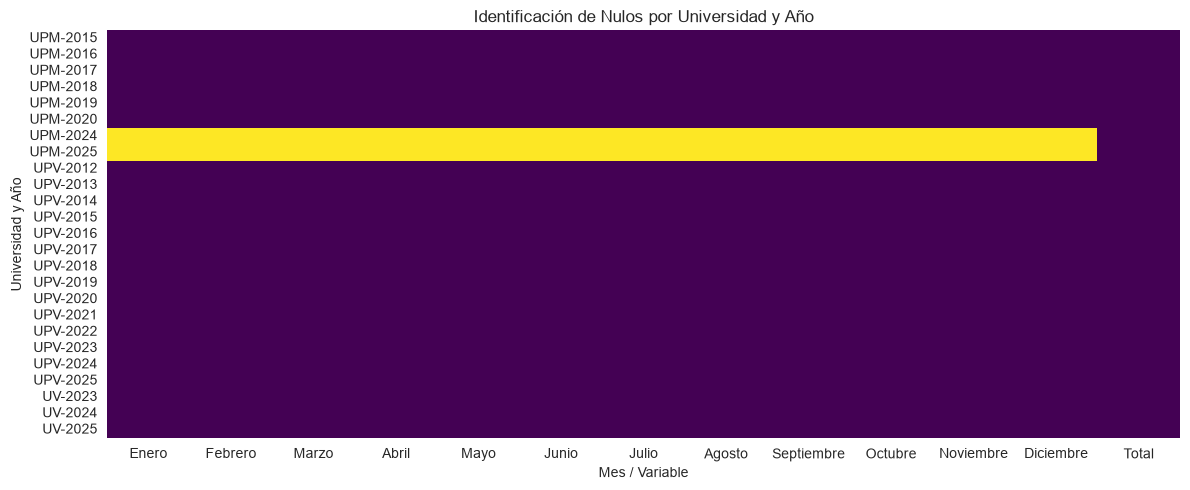

In [2]:
plt.figure(figsize=(12, 5))
sns.heatmap(df.set_index(['Uni', 'Año']).isnull(), cmap='viridis', cbar=False)
plt.title('Identificación de Nulos por Universidad y Año')
plt.xlabel('Mes / Variable')
plt.ylabel('Universidad y Año')
plt.tight_layout()
plt.show()

Para preservar la coherencia de la serie temporal sin perder los totales anuales conocidos, se imputa la distribución mensual aplicando los pesos relativos de estacionalidad histórica que presenta la propia universidad.

In [5]:
meses = ['Enero', 'Febrero', 'Marzo', 'Abril', 'Mayo', 'Junio', 
         'Julio', 'Agosto', 'Septiembre', 'Octubre', 'Noviembre', 'Diciembre']

patron_upm = df[df['Uni'] == 'UPM'][meses].mean()
pesos_upm = patron_upm / patron_upm.sum()

filas_nulas = df['Enero'].isnull() & (df['Uni'] == 'UPM')
for idx in df[filas_nulas].index:
    total_anual = df.loc[idx, 'Total']
    df.loc[idx, meses] = pesos_upm.values * total_anual

df['Total'] = df[meses].sum(axis=1)
df.isnull().sum()

Uni           0
Año           0
Enero         0
Febrero       0
Marzo         0
Abril         0
Mayo          0
Junio         0
Julio         0
Agosto        0
Septiembre    0
Octubre       0
Noviembre     0
Diciembre     0
Total         0
dtype: int64

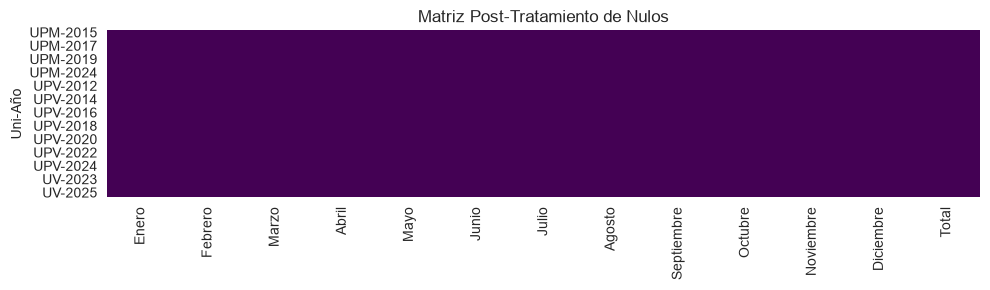

In [6]:
plt.figure(figsize=(10, 3))
sns.heatmap(df.set_index(['Uni', 'Año']).isnull(), cmap='viridis', cbar=False)
plt.title('Matriz Post-Tratamiento de Nulos')
plt.tight_layout()
plt.show()

Para el análisis temporal se transforma la estructura en una serie temporal continua (formato *tidy* o largo), generando un índice mensual de fechas para cada universidad.

In [7]:
mes_a_num = {'Enero': 1, 'Febrero': 2, 'Marzo': 3, 'Abril': 4, 'Mayo': 5, 'Junio': 6,
              'Julio': 7, 'Agosto': 8, 'Septiembre': 9, 'Octubre': 10, 'Noviembre': 11, 'Diciembre': 12}

df_largo = df.melt(id_vars=['Uni', 'Año'], value_vars=meses, var_name='Mes', value_name='Consumo_kWh')
df_largo['Num_Mes'] = df_largo['Mes'].map(mes_a_num)
df_largo['Fecha'] = pd.to_datetime(df_largo['Año'].astype(str) + '-' + df_largo['Num_Mes'].astype(str).str.zfill(2) + '-01')
df_largo = df_largo.sort_values(by=['Uni', 'Fecha']).reset_index(drop=True)
df_largo.head()

,Uni,Año,Mes,Consumo_kWh,Num_Mes,Fecha
0,UPM,2015,Enero,3635911.0,1,2015-01-01
1,UPM,2015,Febrero,3665181.0,2,2015-02-01
2,UPM,2015,Marzo,3351735.0,3,2015-03-01
3,UPM,2015,Abril,2813039.0,4,2015-04-01
4,UPM,2015,Mayo,2978351.0,5,2015-05-01


## 3. Análisis Univariante por Universidad en la Línea del Tiempo

Se analiza la distribución estadística del consumo de energía (kWh) separando por cada universidad, visualizando tanto su dispersión como la estacionalidad característica de cada institución a lo largo de los 12 meses del año.

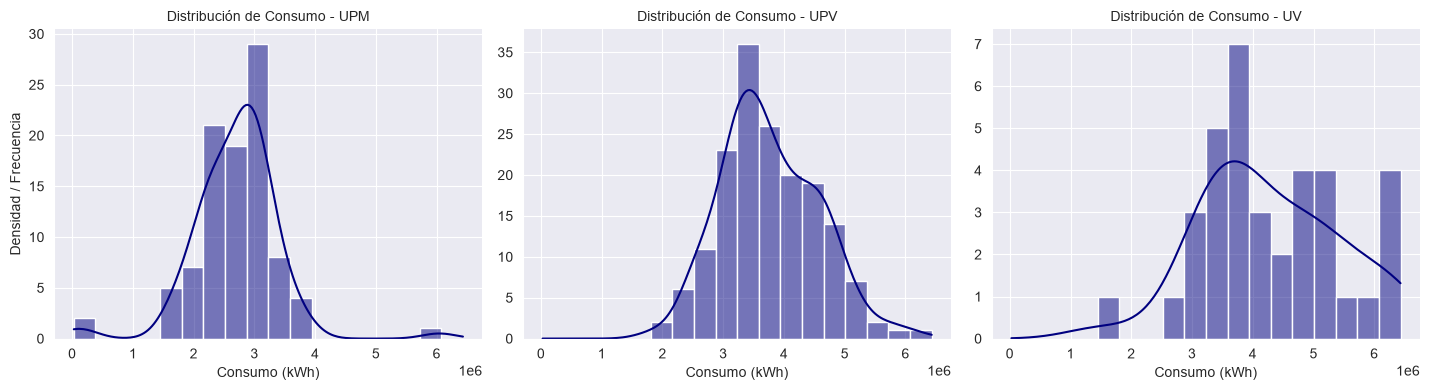

In [8]:
g = sns.displot(data=df_largo, x='Consumo_kWh', col='Uni', kde=True, facet_kws={'sharex': False, 'sharey': False}, height=4, aspect=1.2, color='navy')
g.set_axis_labels('Consumo (kWh)', 'Densidad / Frecuencia')
g.set_titles(col_template='Distribución de Consumo - {col_name}')
plt.tight_layout()
plt.show()

C:\Users\mcarr\AppData\Local\Temp\ipykernel_6796\2472242181.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_largo, x='Uni', y='Consumo_kWh', palette='Set2')


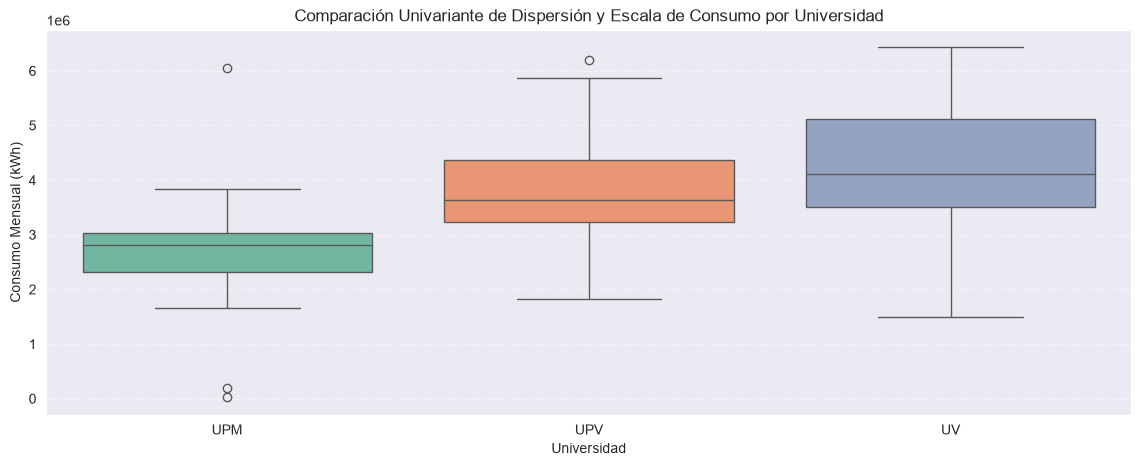

In [15]:
plt.figure(figsize=(14, 5))
sns.boxplot(data=df_largo, x='Uni', y='Consumo_kWh', palette='Set2')
plt.title('Comparación Univariante de Dispersión y Escala de Consumo por Universidad')
plt.xlabel('Universidad')
plt.ylabel('Consumo Mensual (kWh)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

C:\Users\mcarr\AppData\Local\Temp\ipykernel_6796\2579336240.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=datos_uni, x='Mes', y='Consumo_kWh', ax=ax, palette='Blues')
C:\Users\mcarr\AppData\Local\Temp\ipykernel_6796\2579336240.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=datos_uni, x='Mes', y='Consumo_kWh', ax=ax, palette='Blues')
C:\Users\mcarr\AppData\Local\Temp\ipykernel_6796\2579336240.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=datos_uni, x='Mes', y='Consumo_kWh', ax=ax, palette='Blues')


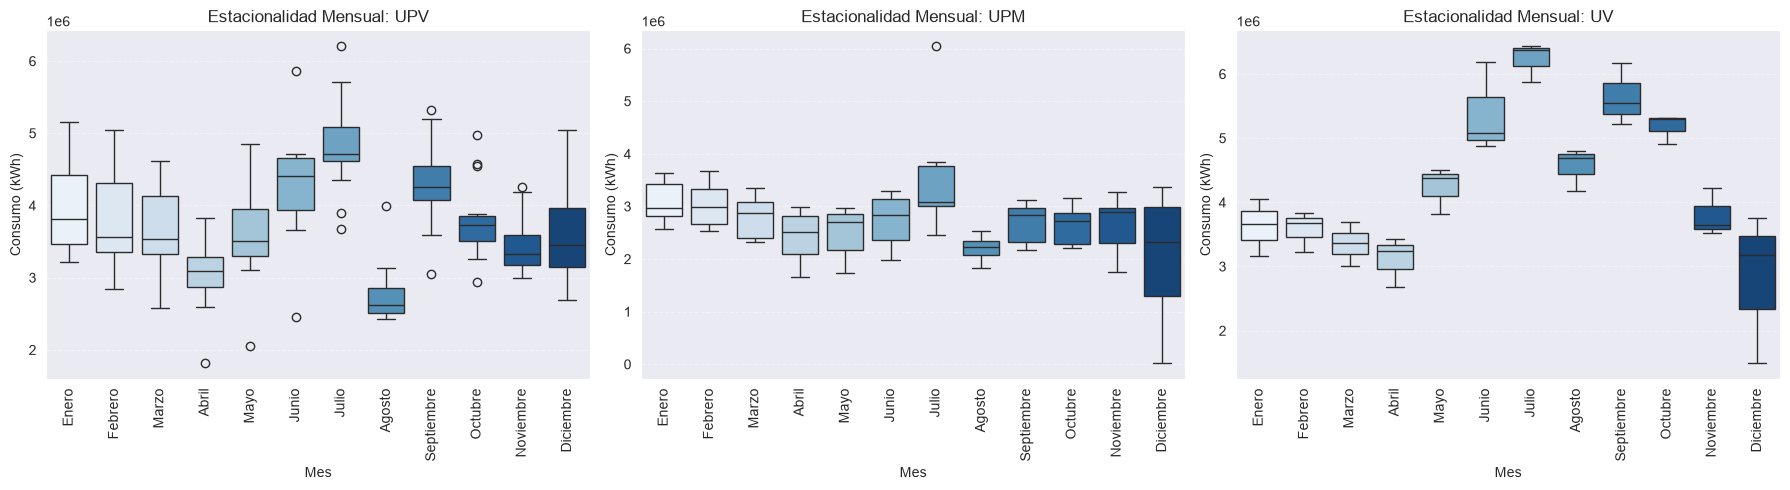

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=False)
universidades = ['UPV', 'UPM', 'UV']

for ax, uni in zip(axes, universidades):
    datos_uni = df_largo[df_largo['Uni'] == uni]
    sns.boxplot(data=datos_uni, x='Mes', y='Consumo_kWh', ax=ax, palette='Blues')
    ax.set_title(f'Estacionalidad Mensual: {uni}')
    ax.set_xlabel('Mes')
    ax.set_ylabel('Consumo (kWh)')
    ax.tick_params(axis='x', rotation=90)
    ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

## 4. Análisis Multivariante y Comparativo en la Línea del Tiempo

Tratándose de series temporales de una variable física, el enfoque multivariante se fundamenta en:
1. La comparación directa de las series en la línea cronológica continua (evolución multiserie temporal).
2. La correlación y comportamiento estacional comparado entre los 12 meses por universidad.
3. La matriz de correlación temporal cruzada entre las trayectorias de consumo de las universidades.

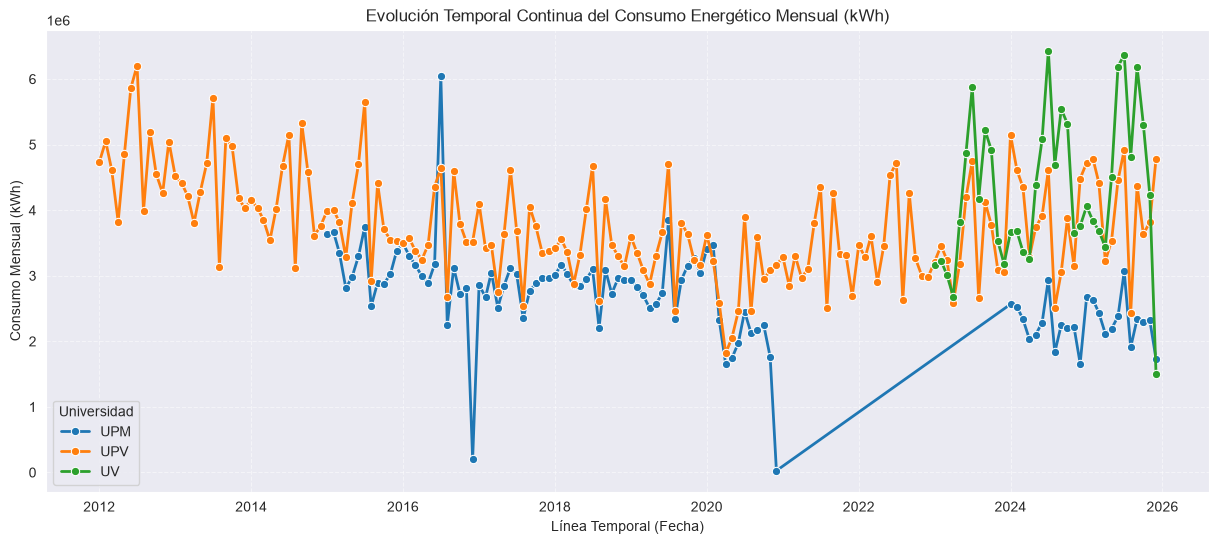

In [11]:
plt.figure(figsize=(15, 6))
sns.lineplot(data=df_largo, x='Fecha', y='Consumo_kWh', hue='Uni', marker='o', linewidth=2)
plt.title('Evolución Temporal Continua del Consumo Energético Mensual (kWh)')
plt.xlabel('Línea Temporal (Fecha)')
plt.ylabel('Consumo Mensual (kWh)')
plt.legend(title='Universidad')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

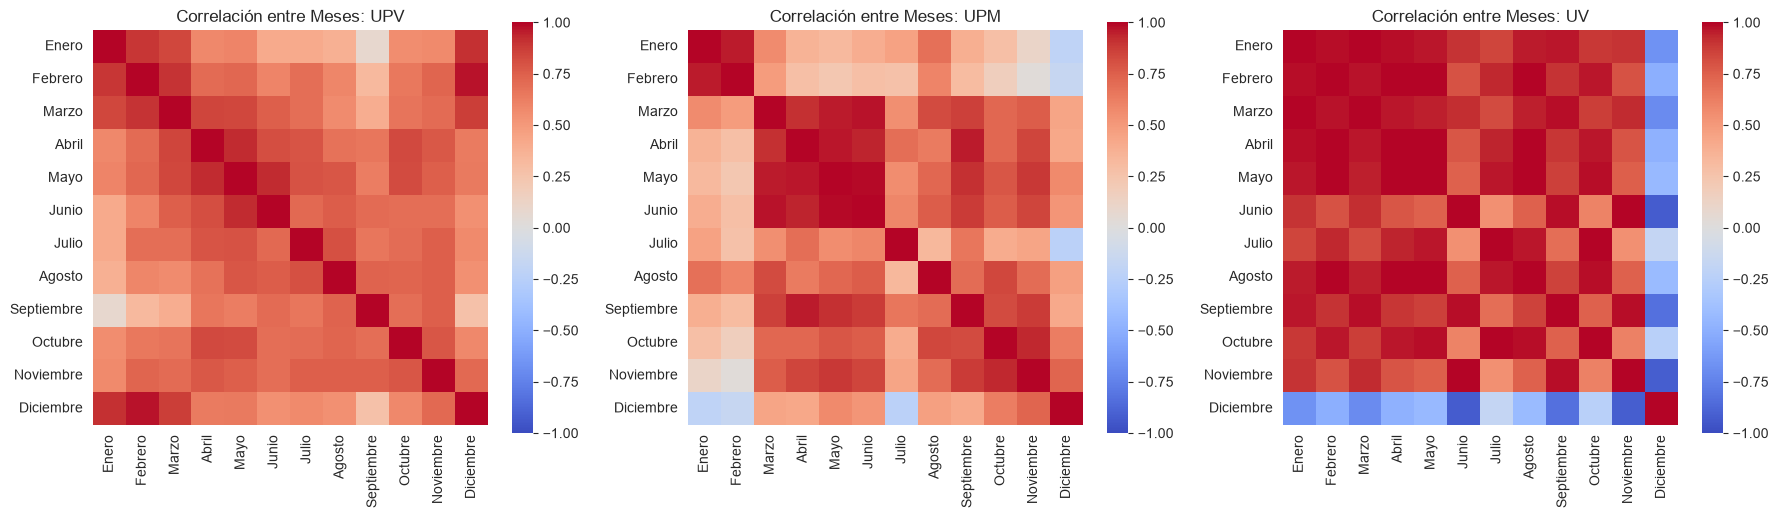

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, uni in zip(axes, universidades):
    datos_piv = df[df['Uni'] == uni][meses]
    corr_mat = datos_piv.corr()
    sns.heatmap(corr_mat, ax=ax, cmap='coolwarm', cbar=True, vmin=-1, vmax=1, square=True)
    ax.set_title(f'Correlación entre Meses: {uni}')
    ax.tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()

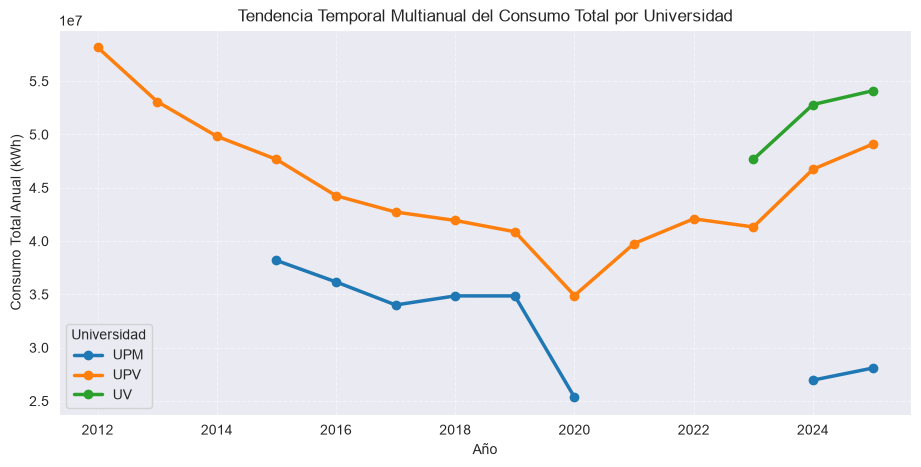

In [13]:
df_anual = df.groupby(['Año', 'Uni'])['Total'].sum().unstack()

fig, ax1 = plt.subplots(figsize=(11, 5))
df_anual.plot(kind='line', marker='o', ax=ax1, linewidth=2.5)
plt.title('Tendencia Temporal Multianual del Consumo Total por Universidad')
plt.xlabel('Año')
plt.ylabel('Consumo Total Anual (kWh)')
plt.legend(title='Universidad')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

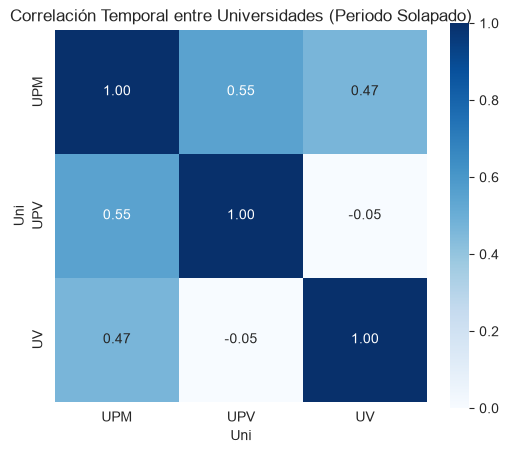

In [14]:
serie_comparada = df_largo.pivot(index='Fecha', columns='Uni', values='Consumo_kWh')
matriz_corr_unis = serie_comparada.dropna().corr()

plt.figure(figsize=(6, 5))
sns.heatmap(matriz_corr_unis, annot=True, fmt='.2f', cmap='Blues', square=True, vmin=0, vmax=1)
plt.title('Correlación Temporal entre Universidades (Periodo Solapado)')
plt.show()